# HW04：PCA 与 UMAP——代码、实际输出与证据边界

姓名：陈乐颜；学号：38720260158045；GitHub：chenleyan33。

本文件按任务 1—4 组织，保留可执行代码、实际计算的表格和内嵌 PNG 图像，末尾包含退出卡、三道作业。

**本机复现**：在 VS Code 右上角“选择内核”中选择 `D:\Anaconda\Anaconda1\python.exe` 对应的 Python 环境，然后选择“全部运行”。数据读取自课程仓库，不额外提交数据副本；运行文件写入仓库根目录的 `.tmp/dimension-reduction/student-results/`。首个单元格会立即显示进度。

**拟合范围**：全体 72 行只用于描述性 PCA/UMAP；诊断标签不传入降维器。预测流程比较只在原始 train 的 38 行内进行三折交叉验证，所有预处理都在 Pipeline 中折内拟合。另 34 行不用于调参或评分。

**初始判断记录**：不同意“二维图分开就证明疾病机制并能预测新患者”；最需要补充独立患者队列的验证。

In [9]:
from pathlib import Path
from datetime import datetime, timezone, timedelta
import hashlib
import json
import os
import sys
import time

STARTED = time.perf_counter()
print("[启动] 正在定位课程数据和加载环境……", flush=True)

def find_repository():
    candidates = [Path.cwd()]
    if "__file__" in globals():
        candidates.insert(0, Path(__file__).resolve().parent)
    if os.environ.get("HW04_REPO_ROOT"):
        candidates.insert(0, Path(os.environ["HW04_REPO_ROOT"]))
    candidates.append(Path(r"C:\Users\陈乐颜\git-practice-classroom"))
    for candidate in candidates:
        for root in (candidate, *candidate.parents):
            if (root / "assignments/hw04/resources/data/leukemia/leukemia.csv").is_file():
                return root
    raise FileNotFoundError(
        "找不到课程数据。请打开 git-practice-classroom 仓库后重试，"
        "或设置 HW04_REPO_ROOT 为你的仓库路径。"
    )

REPO_ROOT = find_repository()
DATA_PATH = REPO_ROOT / "assignments/hw04/resources/data/leukemia/leukemia.csv"
OUTPUT_DIR = REPO_ROOT / ".tmp/dimension-reduction/student-results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
LOCAL_PACKAGES = OUTPUT_DIR / "_packages_vscode"
if not LOCAL_PACKAGES.is_dir():
    LOCAL_PACKAGES = OUTPUT_DIR / "_packages"
if LOCAL_PACKAGES.is_dir():
    sys.path.insert(0, str(LOCAL_PACKAGES))
os.environ.setdefault("MPLCONFIGDIR", str(OUTPUT_DIR / "matplotlib-cache"))
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "1")

from importlib.metadata import version
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import numba
import pynndescent
import scipy
import sklearn
import umap
from sklearn.decomposition import PCA
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

IN_NOTEBOOK = "ipykernel" in sys.modules
if IN_NOTEBOOK:
    from IPython.display import Image, display

def show_table(frame):
    if IN_NOTEBOOK:
        display(frame)
    else:
        print(frame.to_string(index=False), flush=True)

def save_figure(figure, name):
    path = OUTPUT_DIR / name
    figure.tight_layout()
    figure.savefig(path, dpi=180, bbox_inches="tight")
    plt.close(figure)
    if IN_NOTEBOOK:
        display(Image(filename=str(path)))
    print(f"[图已保存] {path}", flush=True)

def plot_embedding(axis, coordinates, labels, title, xlabel, ylabel):
    for label, color in (("ALL", "#287C8E"), ("AML", "#D45D52")):
        mask = labels.eq(label).to_numpy()
        axis.scatter(coordinates[mask, 0], coordinates[mask, 1],
                     c=color, label=label, s=40, alpha=0.86,
                     edgecolors="white", linewidths=0.35)
    axis.set(title=title, xlabel=xlabel, ylabel=ylabel)
    axis.legend(frameon=False)
    axis.grid(alpha=0.18)

VERSIONS = {
    "python": sys.version.split()[0], "numpy": np.__version__,
    "pandas": pd.__version__, "scipy": scipy.__version__,
    "scikit_learn": sklearn.__version__, "umap_learn": version("umap-learn"),
    "pynndescent": version("pynndescent"), "numba": numba.__version__,
    "matplotlib": matplotlib.__version__,
}
RUN_TIME = datetime.now(timezone(timedelta(hours=8))).isoformat(timespec="seconds")
print("执行器：", sys.executable)
print("运行时间（北京时间）：", RUN_TIME)
print("数据：", DATA_PATH)
print("数据 SHA-256：", hashlib.sha256(DATA_PATH.read_bytes()).hexdigest())
show_table(pd.DataFrame(VERSIONS.items(), columns=["software", "version"]))

[启动] 正在定位课程数据和加载环境……
执行器： d:\Anaconda\Anaconda1\python.exe
运行时间（北京时间）： 2026-11-05T13:38:08+08:00
数据： c:\Users\陈乐颜\git-practice-classroom\assignments\hw04\resources\data\leukemia\leukemia.csv
数据 SHA-256： 915bce00295ac470f6bd970a4032730a170a080642a5da53ab0bcb0545156f19


,software,version
0,python,3.14.6
1,numpy,2.4.6
2,pandas,3.0.3
3,scipy,1.18.0
4,scikit_learn,1.9.0
5,umap_learn,NaN
6,pynndescent,NaN
7,numba,0.65.1
8,matplotlib,3.11.0


## 数据准备：输入、样本与使用边界

每行是一份白血病微阵列表达样本，输入为 7,129 个探针，**探针数不等于不同基因数**。排除 `sample_id`、`original_split`、`diagnosis`；不根据诊断筛选探针。教学编号 G001—G072 不是原始患者 ID。

数据来源按课程提供的 `assignments/hw04/resources/data/README.md` 记录：OpenML leukemia，dataset ID 1104，version 1；原研究 Golub et al. (1999), *Science* 286, 531–537。本次直接使用课程 CSV，未重新下载或独立核验原论文全文。

In [10]:
print("[数据准备] 读取并检查 72 × 7,129 输入矩阵", flush=True)
df = pd.read_csv(DATA_PATH)
X = df.drop(columns=["sample_id", "original_split", "diagnosis"])
y = df["diagnosis"]
assert X.shape == (72, 7129), X.shape
assert np.isfinite(X.to_numpy()).all()
assert df["sample_id"].is_unique and X.columns.is_unique
assert X.select_dtypes(include="number").shape == X.shape
assert (X.var(axis=0, ddof=0) > 0).all()
print("输入形状：", X.shape)
print("全部数值有限；探针名唯一；无常量探针。")
print("负值数：", int((X.to_numpy() < 0).sum()))
print("数值范围：", X.to_numpy().min(), X.to_numpy().max())
print("原始划分 × 诊断（仅数据描述）：")
show_table(pd.crosstab(df["original_split"], y).reset_index())
print("诊断计数：", y.value_counts().to_dict())

[数据准备] 读取并检查 72 × 7,129 输入矩阵
输入形状： (72, 7129)
全部数值有限；探针名唯一；无常量探针。
负值数： 147174
数值范围： -28400 71369
原始划分 × 诊断（仅数据描述）：


diagnosis,original_split,ALL,AML
0,test,20,14
1,train,27,11


诊断计数： {'ALL': 47, 'AML': 25}


## 任务 1：降维目的、评价与拟合范围

| 目标 | 需要的输出 | 如何判断有用 |
|---|---|---|
| 可视化 | 二维/三维坐标 | 可读性、局部邻域与参数稳定性；不能把分离当准确率 |
| 去噪 | 抑制不稳定方向后的表示 | 重复测量、独立重建误差或下游验证 |
| 压缩特征 | 少量成分和可复用变换 | 成分数、累计解释率、重建损失与计算成本 |
| 发现样本结构 | 候选簇、梯度、邻域 | 多参数对照，并用独立样本和外部信息验证 |
| 作为后续模型输入 | 可应用到新样本的转换 | 训练折内拟合完整流程，用无泄露验证评价 |

```text
描述当前样本：全部72行表达矩阵
    → 在全部72行拟合标准化 → 在同一矩阵拟合PCA/UMAP → 拟合后按诊断着色

预测新样本：先划分开发与测试数据
    → 每折仅用训练折fit标准化、PCA、分类器
    → 用已拟合的变换transform验证折并predict
    → 锁定方案后评估未参与选择的独立测试队列
```

即使 PCA 不用诊断标签，在全部数据上先拟合也让验证样本参与均值、标准差和协方差估计，从而改变训练样本表示。以下可选对照仅使用原始 38 个 train 样本，采用指定的三折分层交叉验证；原始 test 的 34 行不进入本段训练或评分。

In [11]:
print("[任务1] 原始 train 的 38 行：折内 Pipeline 三折对照", flush=True)
train_mask = df["original_split"].eq("train")
X_train = X.loc[train_mask]
y_train = y.loc[train_mask]
assert len(X_train) == 38
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
cv_rows = []
for fold, (fit_index, validation_index) in enumerate(cv.split(X_train, y_train), 1):
    methods = {
        "StandardScaler -> 1NN": Pipeline([
            ("scale", StandardScaler()), ("knn", KNeighborsClassifier(1))]),
        "StandardScaler -> PCA(10) -> 1NN": Pipeline([
            ("scale", StandardScaler()),
            ("pca", PCA(n_components=10, svd_solver="full")),
            ("knn", KNeighborsClassifier(1))]),
    }
    for name, pipeline in methods.items():
        pipeline.fit(X_train.iloc[fit_index], y_train.iloc[fit_index])
        prediction = pipeline.predict(X_train.iloc[validation_index])
        cv_rows.append({
            "fold": fold, "method": name,
            "balanced_accuracy": float(balanced_accuracy_score(
                y_train.iloc[validation_index], prediction)),
            "fit_n": len(fit_index), "validation_n": len(validation_index),
        })
    print(f"  Fold {fold}/3 完成", flush=True)
cv_frame = pd.DataFrame(cv_rows)
cv_frame.to_csv(OUTPUT_DIR / "training_only_cv.csv", index=False)
show_table(cv_frame)
cv_summary_frame = cv_frame.groupby("method", sort=False)["balanced_accuracy"].agg(
    ["mean", "min", "max"]).reset_index()
print("各方法均值与范围：")
show_table(cv_summary_frame)

[任务1] 原始 train 的 38 行：折内 Pipeline 三折对照
  Fold 1/3 完成
  Fold 2/3 完成
  Fold 3/3 完成


,fold,method,balanced_accuracy,fit_n,validation_n
0,1,StandardScaler -> 1NN,0.819444,25,13
1,1,StandardScaler -> PCA(10) -> 1NN,0.694444,25,13
2,2,StandardScaler -> 1NN,0.875000,25,13
3,2,StandardScaler -> PCA(10) -> 1NN,0.763889,25,13
4,3,StandardScaler -> 1NN,0.833333,26,12
5,3,StandardScaler -> PCA(10) -> 1NN,0.833333,26,12


各方法均值与范围：


,method,mean,min,max
0,StandardScaler -> 1NN,0.842593,0.819444,0.875000
1,StandardScaler -> PCA(10) -> 1NN,0.763889,0.694444,0.833333


**任务 1 解释**：指定的同一三折下，加入 PCA(10) 的流程平均 balanced accuracy 较低。这只描述当前小样本、分类器和划分的结果，不能推论 PCA 普遍降低性能。

## 任务 2：标准化 PCA 与原尺度 PCA 对照

对全部 72 行按探针做 z-score，使用总体标准差 `ddof=0`。这一步不是微阵列上游归一化。矩阵包含负值，本次不直接取 log/log1p，也不把非正值当缺失。

标准化 PCA 与仅中心化的原尺度 PCA 均使用 `svd_solver='full'`。本课把 `components_.T` 定义为方向权重（loading），不是方向系数再乘以特征值平方根的另一种定义。

[任务2] 全部72行的标准化、PCA及原尺度对照
标准化检查： {'max_abs_column_mean': 5.982868521591122e-16, 'max_abs_population_sd_error': 3.3306690738754696e-16}


,input,PC1,PC2,PC1_plus_PC2
0,Standardized,0.149216,0.094462,0.243678
1,Centered raw scale,0.174278,0.103386,0.277664


累计解释率（选定成分数）：


,component,explained_variance_ratio,cumulative_explained_variance_ratio
0,1,0.149216,0.149216
1,2,0.094462,0.243678
4,5,0.034280,0.365014
9,10,0.021499,0.491773
19,20,0.011781,0.641342
49,50,0.006493,0.897234
70,71,0.003376,1.000000


返回成分数： 72 ；解释率>1e-12的成分数： 71
PC1绝对权重前5：standardized


,rank,probe,loading,absolute_loading
0,1,X92518_s_at,0.028786,0.028786
1,2,X95190_at,-0.028177,0.028177
2,3,X98253_at,0.027927,0.027927
3,4,X82895_at,0.027871,0.027871
4,5,Y09616_at,0.027757,0.027757


PC1绝对权重前5：raw


,rank,probe,loading,absolute_loading
0,1,M25079_s_at,0.352388,0.352388
1,2,hum_alu_at,0.313552,0.313552
2,3,HG1428-HT1428_s_at,0.234867,0.234867
3,4,L06499_at,0.210453,0.210453
4,5,J04617_s_at,0.196253,0.196253


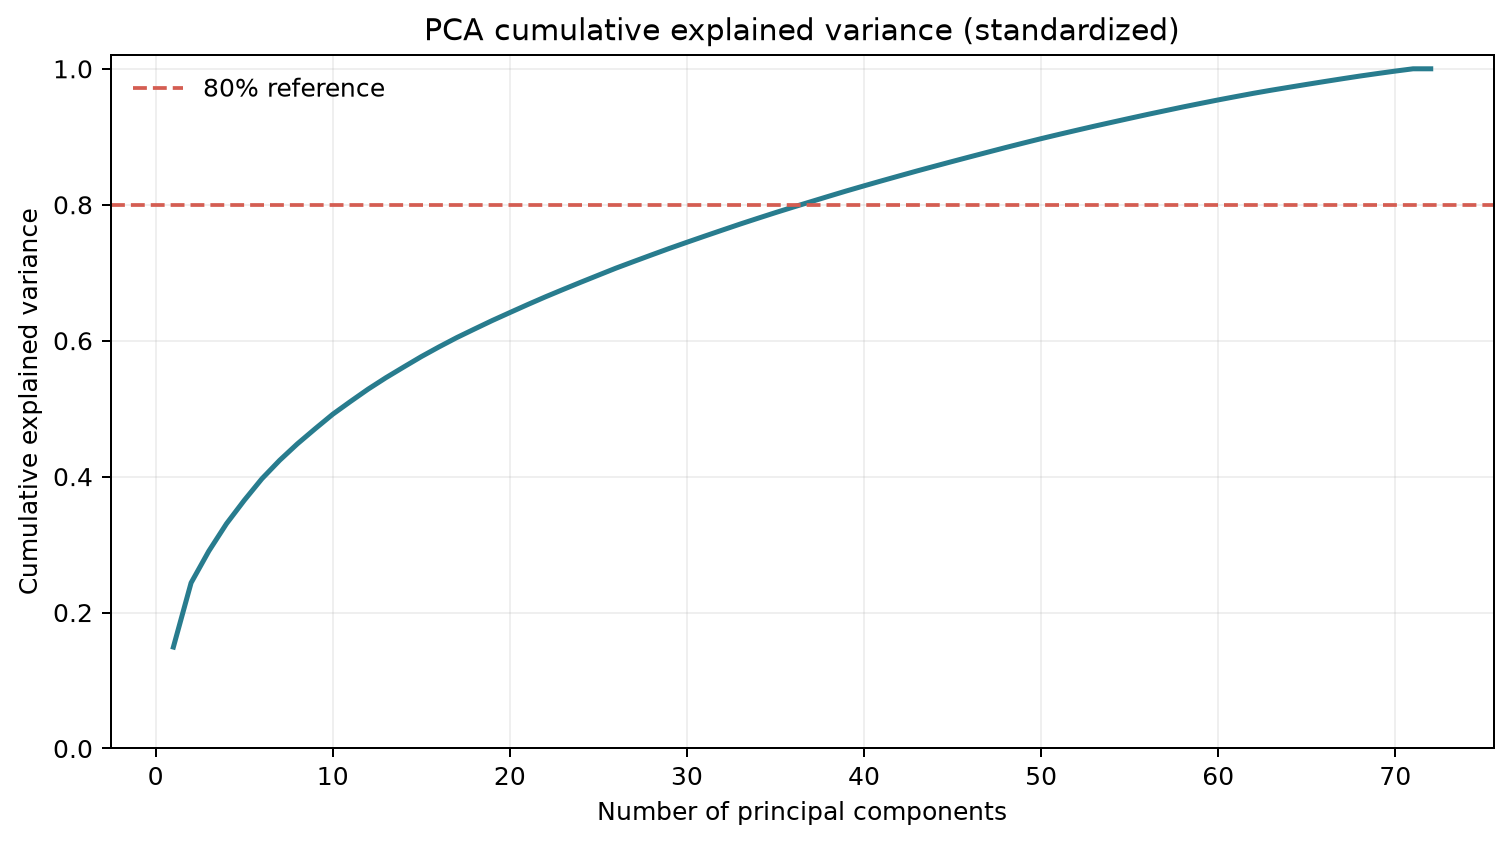

[图已保存] c:\Users\陈乐颜\git-practice-classroom\.tmp\dimension-reduction\student-results\pca_cumulative_variance.png


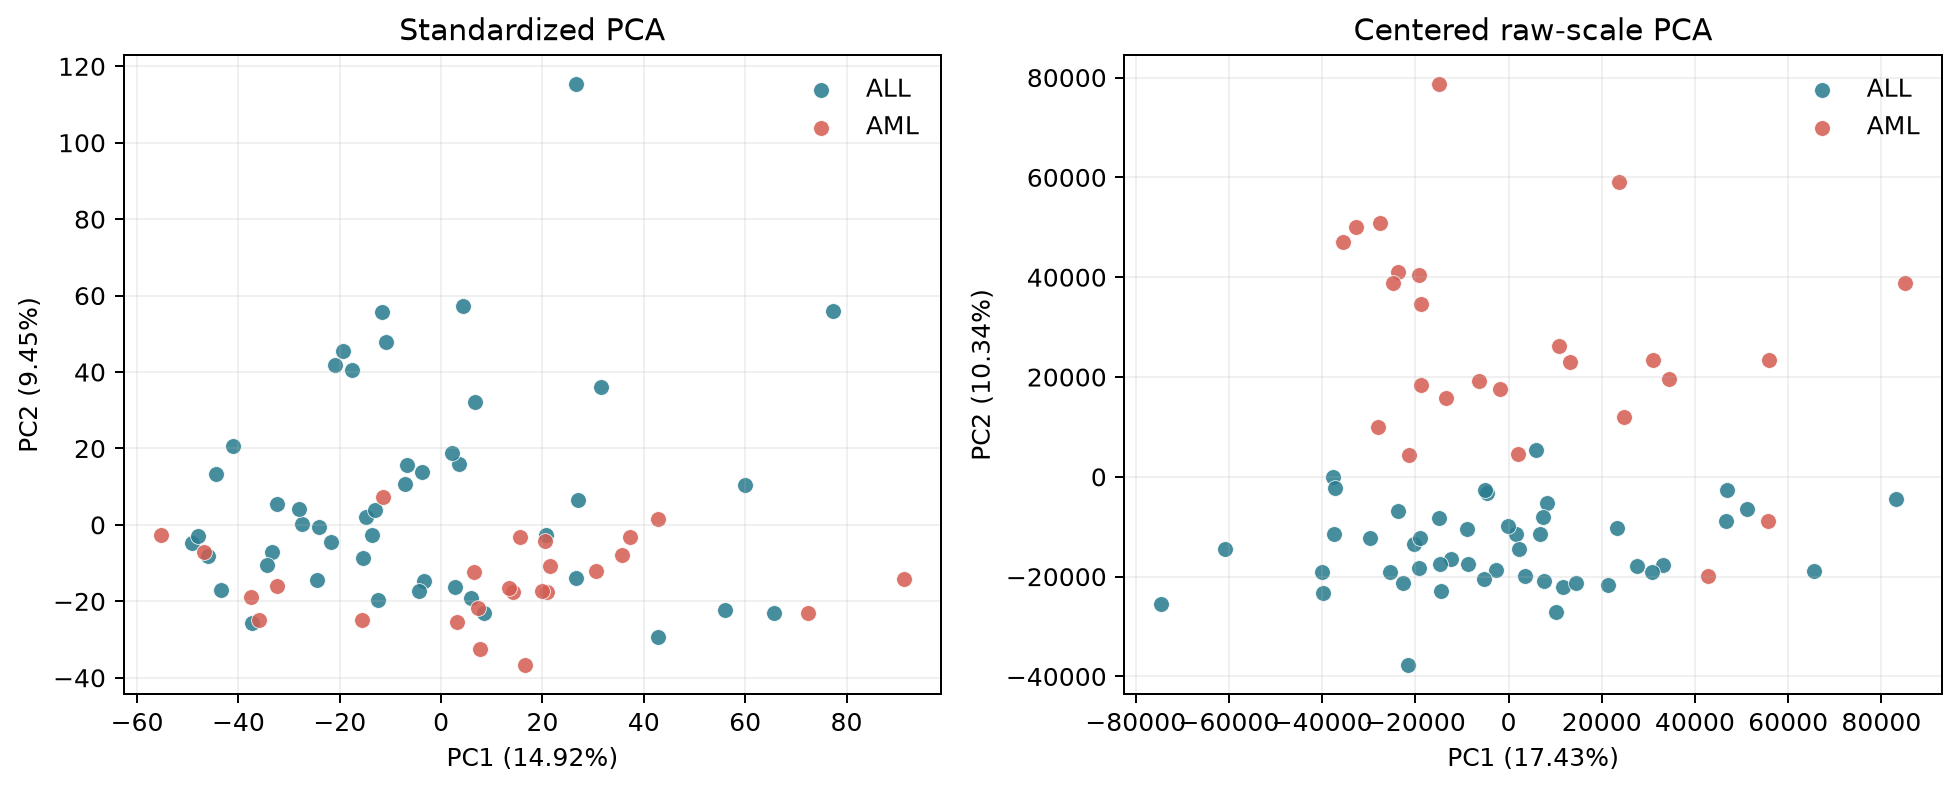

[图已保存] c:\Users\陈乐颜\git-practice-classroom\.tmp\dimension-reduction\student-results\pca_scale_comparison.png


In [12]:
print("[任务2] 全部72行的标准化、PCA及原尺度对照", flush=True)
scaler = StandardScaler()
Z = scaler.fit_transform(X)
scaler_check = {
    "max_abs_column_mean": float(np.abs(Z.mean(axis=0)).max()),
    "max_abs_population_sd_error": float(np.abs(Z.std(axis=0, ddof=0) - 1).max()),
}
print("标准化检查：", scaler_check)
assert scaler_check["max_abs_column_mean"] < 1e-10
assert scaler_check["max_abs_population_sd_error"] < 1e-10
pca = PCA(svd_solver="full")
pca_scores = pca.fit_transform(Z)
raw_pca = PCA(svd_solver="full")
raw_scores = raw_pca.fit_transform(X)  # PCA内部中心化；不进行逐列缩放
evr = pca.explained_variance_ratio_
evr_frame = pd.DataFrame({
    "component": np.arange(1, len(evr) + 1),
    "explained_variance_ratio": evr,
    "cumulative_explained_variance_ratio": evr.cumsum(),
})
evr_frame.to_csv(OUTPUT_DIR / "pca_explained_variance.csv", index=False)
scale_comparison = pd.DataFrame([
    {"input": name, "PC1": model.explained_variance_ratio_[0],
     "PC2": model.explained_variance_ratio_[1],
     "PC1_plus_PC2": model.explained_variance_ratio_[:2].sum()}
    for name, model in (("Standardized", pca), ("Centered raw scale", raw_pca))
])
show_table(scale_comparison)
print("累计解释率（选定成分数）：")
show_table(evr_frame.loc[evr_frame.component.isin([1, 2, 5, 10, 20, 50, 71])])
print("返回成分数：", len(evr), "；解释率>1e-12的成分数：", int((evr > 1e-12).sum()))

def top5_weights(model):
    weights = model.components_[0]
    indices = np.argsort(np.abs(weights))[-5:][::-1]
    return pd.DataFrame({
        "rank": np.arange(1, 6), "probe": X.columns[indices],
        "loading": weights[indices], "absolute_loading": np.abs(weights[indices]),
    })

standardized_loading_frame = top5_weights(pca)
raw_loading_frame = top5_weights(raw_pca)
for name, table in (("standardized", standardized_loading_frame), ("raw", raw_loading_frame)):
    print(f"PC1绝对权重前5：{name}")
    show_table(table)
    table.to_csv(OUTPUT_DIR / f"pc1_top5_{name}.csv", index=False)

figure, axis = plt.subplots(figsize=(8.5, 4.8))
axis.plot(evr_frame.component, evr_frame.cumulative_explained_variance_ratio,
          color="#287C8E", linewidth=2)
axis.axhline(0.8, color="#D45D52", linestyle="--", label="80% reference")
axis.set(xlabel="Number of principal components", ylabel="Cumulative explained variance",
         title="PCA cumulative explained variance (standardized)", ylim=(0, 1.02))
axis.grid(alpha=0.2)
axis.legend(frameon=False)
save_figure(figure, "pca_cumulative_variance.png")

figure, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for axis, scores, model, title in (
    (axes[0], pca_scores, pca, "Standardized PCA"),
    (axes[1], raw_scores, raw_pca, "Centered raw-scale PCA"),
):
    plot_embedding(axis, scores, y, title,
                   f"PC1 ({model.explained_variance_ratio_[0]:.2%})",
                   f"PC2 ({model.explained_variance_ratio_[1]:.2%})")
save_figure(figure, "pca_scale_comparison.png")

**任务 2 解释**：PC1 是使投影样本方差最大的单位方向，并不使用诊断信息来最大化类间分离。其得分为中心化标准特征与方向系数的加权和：`score_i = Σ_j (Z_ij − pca.mean_[j]) × components_[0,j]`，此处 `pca.mean_` 接近零。PC1 不是某一个基因，也不保证是最能区分 ALL/AML 的方向；loading 不是差异表达显著性、预测重要性或致病证据。

整体翻转方向权重和得分的符号，只改变坐标朝向。72 行矩阵中心化后行向量线性相关，因此秩最多为 71，最多有 71 个非零主成分。前两轴只概括约四分之一的标准化方差，不能代表完整表达结构。

原尺度与标准化的 PC1 高权重名单不同：原尺度容易受大方差列支配。标准化减弱这种尺度影响，但也会放大低变异噪声；两者解释率的分母来自不同总方差，不能单凭原尺度的解释率较高就判定它更好。

## 任务 3：UMAP 单因素对照与邻域稳定性

四次拟合使用同一个标准化矩阵 `Z`，不传入诊断标签，均为二维、欧氏距离、`n_jobs=1`。基线为 `n_neighbors=15, min_dist=0.1, random_state=42`；另三次分别只改邻居数为 5、`min_dist` 为 0.5、种子为 7。全部结果都保留，不挑最清楚的一张。

,setting,n_neighbors,min_dist,random_state
0,umap_baseline,15,0.1,42
1,umap_neighbors5,5,0.1,42
2,umap_min_dist05,15,0.5,42
3,umap_seed7,15,0.1,7


[任务3] UMAP 1/4：umap_baseline；首次编译可能需要等待……
  umap_baseline 完成
[任务3] UMAP 2/4：umap_neighbors5；首次编译可能需要等待……
  umap_neighbors5 完成
[任务3] UMAP 3/4：umap_min_dist05；首次编译可能需要等待……
  umap_min_dist05 完成
[任务3] UMAP 4/4：umap_seed7；首次编译可能需要等待……
  umap_seed7 完成
样本编号—坐标表（完整72行见导出的CSV）：


,sample_id,original_split,diagnosis,pca1,pca2,umap_baseline_1,umap_baseline_2,umap_neighbors5_1,umap_neighbors5_2,umap_min_dist05_1,umap_min_dist05_2,umap_seed7_1,umap_seed7_2
0,G001,train,ALL,27.105207,6.448490,7.527618,1.749259,10.055384,1.022408,4.242846,6.732675,0.928812,5.430337
1,G002,train,ALL,3.507419,15.845801,7.233461,0.753453,9.536812,2.273381,4.321175,8.143794,1.712362,6.443752
2,G003,train,ALL,60.006379,10.392307,7.544736,1.512743,9.701388,1.346992,4.501159,6.984841,1.285627,5.706972
3,G004,train,ALL,20.640386,-2.623372,7.338019,2.063425,10.379709,0.996700,4.019698,6.123560,1.241458,5.141459
4,G005,train,ALL,-21.012018,41.794160,7.786791,0.032986,6.518684,0.503266,4.863666,9.381099,1.409877,7.700765
5,G006,train,ALL,-3.459711,-14.757167,6.569427,1.620422,10.239114,1.679315,2.807701,7.310422,2.052515,5.684464
6,G007,train,ALL,26.618490,-13.925799,7.475513,2.531527,10.533683,0.820188,3.195461,6.133496,1.158930,4.711481
7,G008,train,ALL,56.070618,-22.143024,7.417565,2.345038,10.449578,0.987603,3.555630,6.223211,0.964082,4.834943


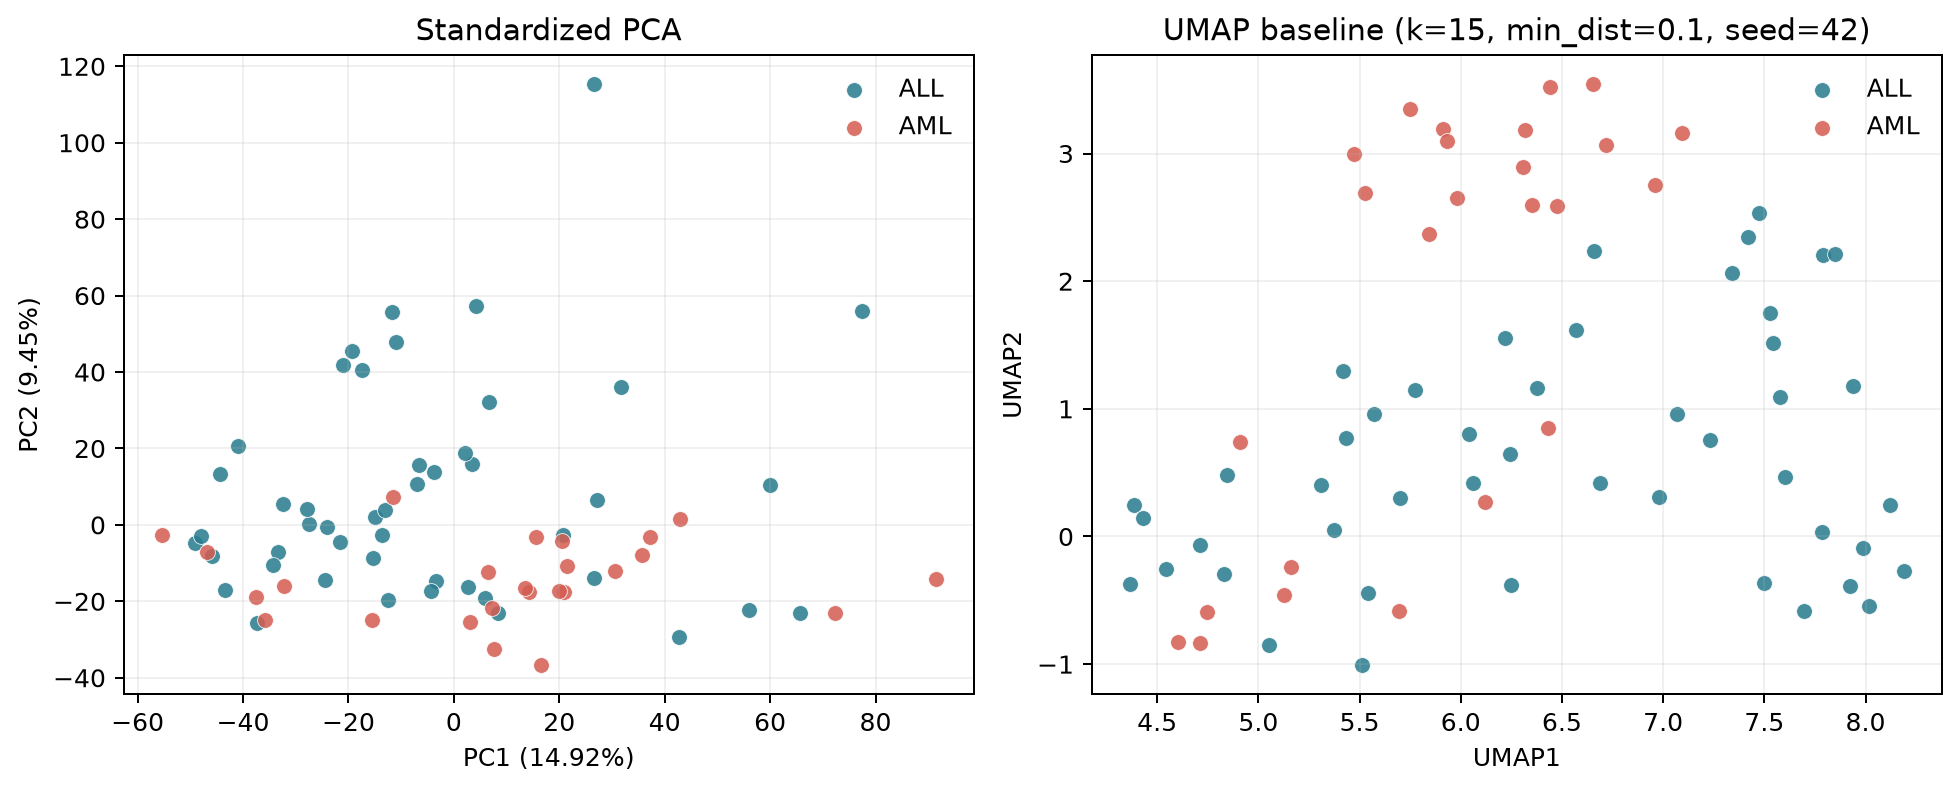

[图已保存] c:\Users\陈乐颜\git-practice-classroom\.tmp\dimension-reduction\student-results\pca_vs_umap.png


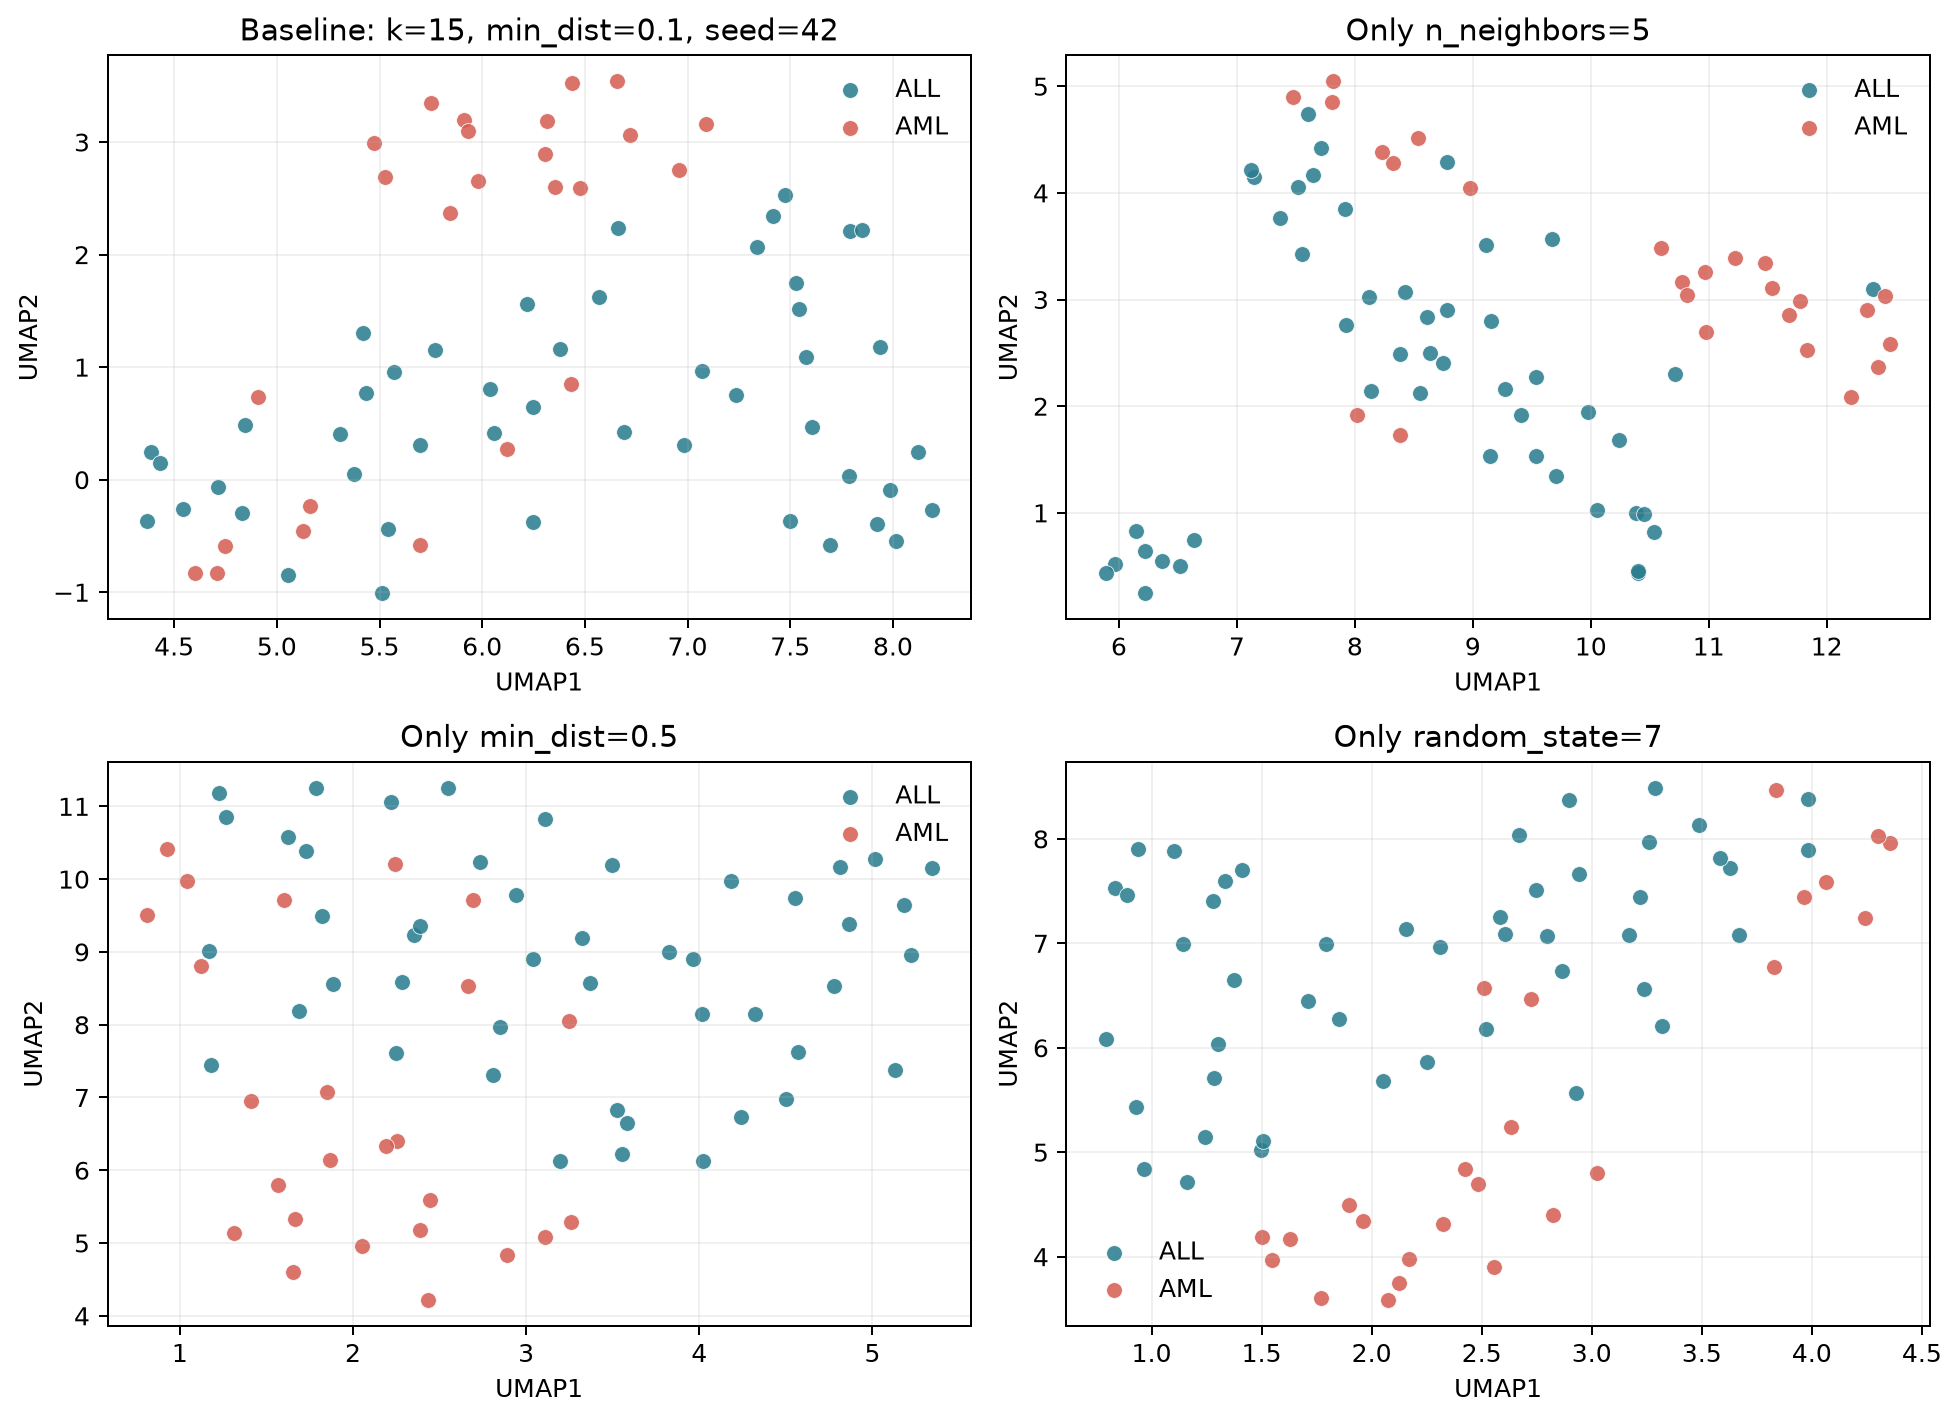

[图已保存] c:\Users\陈乐颜\git-practice-classroom\.tmp\dimension-reduction\student-results\umap_parameter_comparison.png


In [13]:
umap_specs = {
    "umap_baseline": {"n_neighbors": 15, "min_dist": 0.1, "random_state": 42},
    "umap_neighbors5": {"n_neighbors": 5, "min_dist": 0.1, "random_state": 42},
    "umap_min_dist05": {"n_neighbors": 15, "min_dist": 0.5, "random_state": 42},
    "umap_seed7": {"n_neighbors": 15, "min_dist": 0.1, "random_state": 7},
}
show_table(pd.DataFrame.from_dict(umap_specs, orient="index").rename_axis("setting").reset_index())
embeddings = {}
for number, (name, parameters) in enumerate(umap_specs.items(), 1):
    print(f"[任务3] UMAP {number}/4：{name}；首次编译可能需要等待……", flush=True)
    embeddings[name] = umap.UMAP(
        n_components=2, metric="euclidean", n_jobs=1, **parameters
    ).fit_transform(Z)
    assert embeddings[name].shape == (72, 2) and np.isfinite(embeddings[name]).all()
    print(f"  {name} 完成", flush=True)

coordinate_frame = df[["sample_id", "original_split", "diagnosis"]].copy()
coordinate_frame["pca1"] = pca_scores[:, 0]
coordinate_frame["pca2"] = pca_scores[:, 1]
for name, coordinates in embeddings.items():
    coordinate_frame[f"{name}_1"] = coordinates[:, 0]
    coordinate_frame[f"{name}_2"] = coordinates[:, 1]
coordinate_frame.to_csv(OUTPUT_DIR / "sample_coordinates.csv", index=False)
print("样本编号—坐标表（完整72行见导出的CSV）：")
show_table(coordinate_frame.head(8))

figure, axes = plt.subplots(1, 2, figsize=(11, 4.5))
plot_embedding(axes[0], pca_scores, y, "Standardized PCA",
               f"PC1 ({evr[0]:.2%})", f"PC2 ({evr[1]:.2%})")
plot_embedding(axes[1], embeddings["umap_baseline"], y,
               "UMAP baseline (k=15, min_dist=0.1, seed=42)", "UMAP1", "UMAP2")
save_figure(figure, "pca_vs_umap.png")

titles = ["Baseline: k=15, min_dist=0.1, seed=42", "Only n_neighbors=5",
          "Only min_dist=0.5", "Only random_state=7"]
figure, axes = plt.subplots(2, 2, figsize=(11, 8))
for axis, (name, coordinates), title in zip(axes.flat, embeddings.items(), titles):
    plot_embedding(axis, coordinates, y, title, "UMAP1", "UMAP2")
save_figure(figure, "umap_parameter_comparison.png")

为避免把旋转、翻转后的坐标直接相减，本次比较每个样本在各嵌入中的 10 个最近邻：共享比例为 `|N_baseline ∩ N_comparison| / 10`，再对 72 个样本求均值和中位数；Jaccard 为交集/并集。同时比较基线嵌入与原始标准化高维空间的 10 近邻，描述局部保真程度。

无向稳定样本对定义为：在四种设置的**每一种**中，至少一个样本把另一个列为 10 近邻；不要求每种设置都互为近邻。这个定义不是独立性检验或显著性检验。

In [14]:
print("[任务3] 计算10近邻共享比例与共同保留的样本对", flush=True)
def nearest_sets(points, k=10):
    indices = NearestNeighbors(n_neighbors=k + 1).fit(points).kneighbors(
        points, return_distance=False)
    return [set(int(j) for j in row if j != i) for i, row in enumerate(indices)]

def overlap_summary(reference, comparison):
    shared = [len(a & b) / len(a) for a, b in zip(reference, comparison)]
    jaccard = [len(a & b) / len(a | b) for a, b in zip(reference, comparison)]
    return {
        "mean_shared_neighbors_percent": float(np.mean(shared) * 100),
        "median_shared_neighbors_percent": float(np.median(shared) * 100),
        "mean_jaccard": float(np.mean(jaccard)),
        "median_jaccard": float(np.median(jaccard)),
    }

embedding_neighbors = {name: nearest_sets(points) for name, points in embeddings.items()}
assert all(len(neighbors) == 10 for rows in embedding_neighbors.values() for neighbors in rows)
baseline_neighbors = embedding_neighbors["umap_baseline"]
high_neighbors = nearest_sets(Z)
high_shared = overlap_summary(high_neighbors, baseline_neighbors)["mean_shared_neighbors_percent"]
neighborhood_rows = []
for name, neighbors in embedding_neighbors.items():
    neighborhood_rows.append({
        "comparison": name, **overlap_summary(baseline_neighbors, neighbors),
        "high_dimensional_mean_shared_neighbors_percent": high_shared if name == "umap_baseline" else None,
    })
neighborhood_frame = pd.DataFrame(neighborhood_rows)
neighborhood_frame.to_csv(OUTPUT_DIR / "umap_neighbor_stability.csv", index=False)
show_table(neighborhood_frame)
print(f"基线UMAP与高维标准化空间的平均共享10近邻比例：{high_shared:.2f}%")

pair_settings = {}
for name, rows in embedding_neighbors.items():
    for i, neighbors in enumerate(rows):
        for j in neighbors:
            pair_settings.setdefault(tuple(sorted((i, j))), set()).add(name)
pair_rows = [
    {"sample_id_1": df.loc[i, "sample_id"], "sample_id_2": df.loc[j, "sample_id"],
     "settings_count": len(settings),
     "settings": ", ".join(name for name in umap_specs if name in settings),
     "same_diagnosis": bool(y.iloc[i] == y.iloc[j])}
    for (i, j), settings in pair_settings.items()
]
stable_pair_frame = pd.DataFrame(pair_rows).sort_values(
    ["settings_count", "sample_id_1", "sample_id_2"], ascending=[False, True, True])
stable_pair_frame.to_csv(OUTPUT_DIR / "umap_neighbor_pairs.csv", index=False)
stable_pairs = stable_pair_frame.loc[stable_pair_frame.settings_count.eq(4)]
print("四种设置共同保留的无向样本对：", len(stable_pairs))
print("同诊断 / 不同诊断对数：", int(stable_pairs.same_diagnosis.sum()),
      "/", int((~stable_pairs.same_diagnosis).sum()))
show_table(stable_pairs.head(12))

[任务3] 计算10近邻共享比例与共同保留的样本对


,comparison,mean_shared_neighbors_percent,median_shared_neighbors_percent,mean_jaccard,median_jaccard,high_dimensional_mean_shared_neighbors_percent
0,umap_baseline,100.000000,100.0,1.000000,1.000000,45.972222
1,umap_neighbors5,62.083333,70.0,0.471450,0.538462,NaN
2,umap_min_dist05,67.638889,70.0,0.538360,0.538462,NaN
3,umap_seed7,67.638889,70.0,0.541181,0.538462,NaN


基线UMAP与高维标准化空间的平均共享10近邻比例：45.97%
四种设置共同保留的无向样本对： 205
同诊断 / 不同诊断对数： 182 / 23


,sample_id_1,sample_id_2,settings_count,settings,same_diagnosis
0,G001,G003,4,"umap_baseline, umap_neighbors5, umap_min_dist0...",True
1,G001,G004,4,"umap_baseline, umap_neighbors5, umap_min_dist0...",True
3,G001,G007,4,"umap_baseline, umap_neighbors5, umap_min_dist0...",True
4,G001,G008,4,"umap_baseline, umap_neighbors5, umap_min_dist0...",True
5,G001,G009,4,"umap_baseline, umap_neighbors5, umap_min_dist0...",True
9,G001,G027,4,"umap_baseline, umap_neighbors5, umap_min_dist0...",True
7,G001,G049,4,"umap_baseline, umap_neighbors5, umap_min_dist0...",True
10,G002,G003,4,"umap_baseline, umap_neighbors5, umap_min_dist0...",True
13,G002,G009,4,"umap_baseline, umap_neighbors5, umap_min_dist0...",True
15,G002,G011,4,"umap_baseline, umap_neighbors5, umap_min_dist0...",True


| 比较维度 | PCA | UMAP |
|---|---|---|
| 线性/非线性 | 线性正交投影 | 非线性嵌入 |
| 主要信息 | 最大化投影方差的全局方向 | 高维近邻图的局部结构 |
| 坐标轴含义 | 输入特征的线性组合 | 嵌入坐标，不是特定基因或疾病轴 |
| 方差解释率 | 可以报告 | 没有与 PCA 同义的方差解释率 |
| 局部与全局关系 | 低维投影也会丢失邻近关系 | 部分局部关系保留，全局距离不能直接量化生物差异 |
| 参数与随机性 | 本次 full SVD；成分正负号可翻转 | 邻居数、min_dist、种子均会影响布局 |
| 预测时防泄露 | 在训练折拟合，再变换验证/新样本 | 同样在训练折拟合，再变换验证/新样本并独立评价 |

**任务 3 的三条判断：**

1. 图和邻域统计支持“指定预处理及参数下，一部分局部关系可重复出现”，可用于探索候选结构。改变参数后近邻也有变化，不能说全部结构稳定。
2. 图不能证明岛屿数量就是真实亚型数；方向、面积、密度、岛屿间距离不是校准过的生物量尺。不同坐标范围也不能直接拿来比较生物效应大小。
3. 图的分离不能证明机制或新患者预测性能。本数据缺少批次、中心及可核验的患者重复字段，不能宣称已排除批次影响或确认患者层面的独立性。

UMAP 常用于单细胞或复杂表型展示，是因为高维数据中局部邻域可能比单个线性方向更便于探索，但二维展示不是独立的机制或临床验证。

## 任务 4：主张—证据—推理—边界（退出卡）

以下四句的数值从本次运行变量生成。

In [15]:
print("[任务4] 用当前运行结果生成四句退出卡", flush=True)
nn5 = neighborhood_frame.loc[neighborhood_frame.comparison.eq("umap_neighbors5")].iloc[0]
conclusions = [
    "主张：二维图中的分离是探索线索，不能据此证明疾病机制或新患者预测能力。",
    f"证据：标准化PCA的PC1/PC2解释率为{evr[0]:.2%}/{evr[1]:.2%}，"
    f"合计{evr[:2].sum():.2%}；UMAP只把n_neighbors从15改为5时，"
    f"相对基线的平均共享10近邻比例为{nn5.mean_shared_neighbors_percent:.2f}%。",
    "推理：前两主成分只概括部分方差，而嵌入近邻对设置也敏感，因此图形关联只能提出假设，不能取代预测验证或因果实验。",
    "边界：当前缺少批次和患者重复映射；应预先锁定全流程，在独立、多中心患者队列上检验泛化，并用干预或功能实验验证候选机制。",
]
for line in conclusions:
    print(line)

cv_summary = {}
for method, group in cv_frame.groupby("method", sort=False):
    values = group.balanced_accuracy
    cv_summary[method] = {
        "fold_scores": values.tolist(), "mean": float(values.mean()),
        "minimum": float(values.min()), "maximum": float(values.max()),
    }
summary = {
    "run_time_beijing": RUN_TIME,
    "python_executable": sys.executable,
    "data_sha256": hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
    "data": {"samples": len(df), "features": X.shape[1],
             "class_counts": y.value_counts().sort_index().to_dict(),
             "train_n": int(train_mask.sum()),
             "train_class_counts": y_train.value_counts().sort_index().to_dict()},
    "versions": VERSIONS, "scaler_check": scaler_check,
    "standardized_pca": {
        "pc1_evr": float(evr[0]), "pc2_evr": float(evr[1]),
        "pc1_pc2_sum": float(evr[:2].sum()), "components_returned": len(evr),
        "nonzero_components_numerical": int((evr > 1e-12).sum()),
        "top5_loadings": standardized_loading_frame.to_dict(orient="records"),
        "first_components_cumulative": {str(n): float(evr[:n].sum()) for n in [1, 2, 5, 10, 20, 50, 71]},
    },
    "raw_scale_pca": {
        "pc1_evr": float(raw_pca.explained_variance_ratio_[0]),
        "pc2_evr": float(raw_pca.explained_variance_ratio_[1]),
        "pc1_pc2_sum": float(raw_pca.explained_variance_ratio_[:2].sum()),
        "top5_loadings": raw_loading_frame.to_dict(orient="records"),
    },
    "umap": {"parameters": umap_specs, "neighbor_k": 10,
             "stability": neighborhood_rows,
             "pairs_present_in_all_settings": len(stable_pairs),
             "top_stable_pairs": stable_pairs.head(12).to_dict(orient="records")},
    "training_only_cv": cv_summary,
    "conclusions": conclusions,
}
(OUTPUT_DIR / "summary.json").write_text(
    json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"[完成] 耗时 {time.perf_counter() - STARTED:.1f} 秒", flush=True)
print(f"Outputs written to: {OUTPUT_DIR}", flush=True)

[任务4] 用当前运行结果生成四句退出卡
主张：二维图中的分离是探索线索，不能据此证明疾病机制或新患者预测能力。
证据：标准化PCA的PC1/PC2解释率为14.92%/9.45%，合计24.37%；UMAP只把n_neighbors从15改为5时，相对基线的平均共享10近邻比例为62.08%。
推理：前两主成分只概括部分方差，而嵌入近邻对设置也敏感，因此图形关联只能提出假设，不能取代预测验证或因果实验。
边界：当前缺少批次和患者重复映射；应预先锁定全流程，在独立、多中心患者队列上检验泛化，并用干预或功能实验验证候选机制。
[完成] 耗时 35.8 秒
Outputs written to: c:\Users\陈乐颜\git-practice-classroom\.tmp\dimension-reduction\student-results


## 三道课后作业

1. **PCA 第一主成分代表什么**：PC1 是使输入投影方差最大的单位方向。本次标准化 PC1 解释约 14.92% 方差，`X92518_s_at` 的方向权重约为 +0.028786，意味着固定其他标准化特征时，该探针的标准化值增加 1 会为 PC1 得分增加该系数的贡献。得分由全部探针共同决定，不能将这个探针称为致病基因，也不能把 PC1 当作最优诊断方向；符号整体翻转后解释等价。
2. **为什么 PCA 前要考虑标准化**：原尺度 PC1/PC2 解释率约为 17.43%/10.34%，标准化后约为 14.92%/9.45%；原尺度 PC1 的首位探针是 `M25079_s_at`，标准化后为 `X92518_s_at`。这说明尺度影响主方向。标准化让各探针方差接近 1，减弱大方差探针支配，但可能放大低变异噪声；不能仅凭解释率大小判断哪一种更有生物意义。
3. **UMAP 能说明什么、不能说明什么**：只把邻居数从 15 改到 5，平均共享 10 近邻约为 62.08%，中位共享比例为 70%，说明存在重复出现的局部关系，也存在对设置敏感的关系。它不能给出 PCA 式解释率，岛屿距离、轴方向和岛屿数不能直接解释成生物距离、机制或真实亚型数，更不能替代对新患者的无泄露验证。

## 运行与核查记录

- 具体执行时间、解释器路径、软件版本及数据 SHA-256 保留在首个单元格的实际输出。
- UMAP 基线随机种子 42，对照种子 7；交叉验证使用 `StratifiedKFold(3, shuffle=True, random_state=42)`。PCA 使用 full SVD。
- 运行时 CSV、JSON 与 PNG 写入课程规定的 `.tmp/dimension-reduction/student-results/`；notebook 已内嵌图像和表格，关闭内核后仍可阅读。
- 代码对输入矩阵、有限值、标准化均值/标准差、嵌入形状及近邻数量做检查；所有报告数值来自运行。跨版本可能存在浮点数、坐标或符号差异，应以实际输出为准。